In [12]:
import os
import pandas as pd
from Bio import Seq,SeqIO
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter
from matplotlib.colors import ListedColormap
import matplotlib as mpl
import logomaker
%matplotlib inline
%config InlineBackend.figure_format = 'png'
plt.rcParams['svg.fonttype'] = 'none'
mpl.rcParams['figure.dpi']= 300

## Make aln figure

In [2]:
aln = [rec for rec in SeqIO.parse('../data/ISPmu1_locus_aln.fna', 'fasta')]

In [3]:
aln_reshaped = [[str(rec.seq)[i] for rec in aln] for i in range(len(aln[0]))]

In [4]:
perc_ids = [pd.Series(Counter(w)).divide(len(aln)) for w in aln_reshaped]

In [5]:
perc_id_matrix = [[perc_ids[n].loc[b] if b!='-' else 0 for b in col] for n,col in enumerate(aln_reshaped)]

In [6]:
perc_id_matrix = np.transpose(perc_id_matrix)

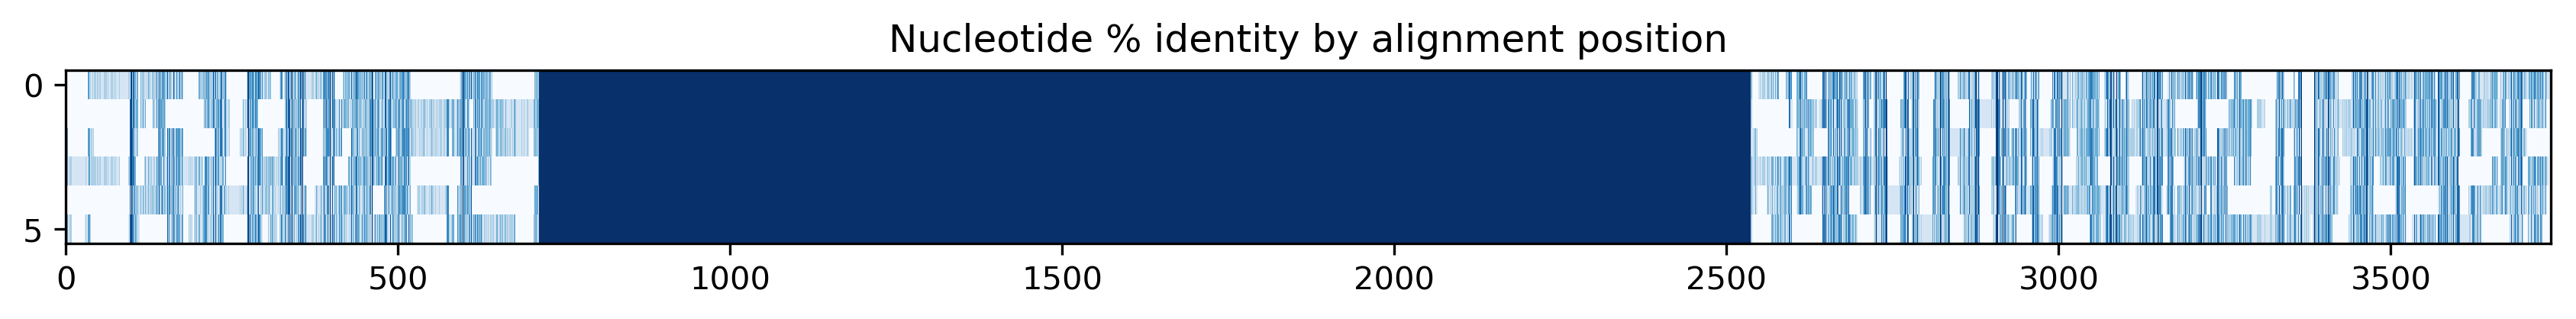

In [13]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(14, 1))
ax.imshow(perc_id_matrix, cmap='Blues', aspect='auto')

ax.set_title('Nucleotide % identity by alignment position')
plt.show()

In [8]:
def make_freq_df(aln_matrix):
    count_by_pos = [Counter([b for b in aln_col if b not in 'N-']) for aln_col in aln_matrix]
    freq_by_pos = []
    for c in count_by_pos:
        for b in 'ACGT':
            if b not in c:
                c[b]=0
        counts = pd.Series(c)[list('ACGT')]
        freq_by_pos.append(counts/sum(counts))
    return pd.DataFrame(freq_by_pos)

In [9]:
def make_consensus_aln(aln_matrix):
    aln_sequences = [''.join([aln_matrix[i][j] for i in range(len(aln_matrix))]) for j in range(len(aln_matrix[0]))]
    # ["white", "lightgreen", "tomato", "lightskyblue", "lemonchiffon"]
    base_colors = {'A':'#ffffff', 'G':'#ffffff', 'T':'#ffffff', 'C':'#ffffff', '-':'#ffffff', 'N':'#ffffff'}
    base_color_idx = {k:n for n,k in enumerate(base_colors.keys())}
    base_colormap = ListedColormap(base_colors.values())
    col_matrix = [[base_color_idx[b] for b in s] for s in aln_sequences]
    freq_by_pos = make_freq_df(aln_matrix)
    
    fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(6, 1+0.5*len(aln_matrix[0])), gridspec_kw={
        'height_ratios': [1, 0.5*len(aln_matrix[0])]})

    # create Logo object
    seq_info = logomaker.transform_matrix(freq_by_pos, from_type='probability', to_type='information')
    occupacy = [sum([b not in 'N-' for b in aln_col])/len(aln_col) for aln_col in aln_matrix]
    seq_info = seq_info.multiply(occupacy, axis=0)
    seq_logo = logomaker.Logo(seq_info, ax=axes[0])

    # style using Logo methods
    seq_logo.style_spines(visible=False)
    seq_logo.style_spines(spines=['left', 'bottom'], visible=True)
    seq_logo.style_xticks(fmt='%d', anchor=0)
    seq_logo.ax.set_xticklabels([i for i in np.arange(-9,11)], size=10)

    for y in seq_logo.ax.get_yticklabels():
        y.set_size(10)

    seq_logo.ax.spines['bottom'].set_linewidth(1)
    seq_logo.ax.spines['left'].set_linewidth(1)

    seq_logo.ax.tick_params(width=1, length=5)
    seq_logo.ax.set_ylim(0,2)
    #seq_logo.ax.set_xticks([])

    #seq_logo.ax.vlines(9.5, 0, 2, color='k', linestyle='dotted')

    # style using Axes methods
    seq_logo.ax.set_ylabel("bits", size=10)

    # aln
    axes[1].imshow(col_matrix, cmap=base_colormap)
    for i in range(len(aln_sequences)):
        for j in range(len(aln_sequences[i])):
            axes[1].text(j, i, aln_sequences[i][j], ha="center", va="center", color="k")
    for s in ['top', 'bottom', 'right', 'left']:
        axes[1].spines[s].set_visible(False)
    axes[1].set_xticks([])
    axes[1].set_yticks([])

    #plt.vlines(9.5, -0.5, len(aln_sequences)-0.5, color='k', linestyle='dotted')

    plt.subplots_adjust(hspace=0)
    plt.show()

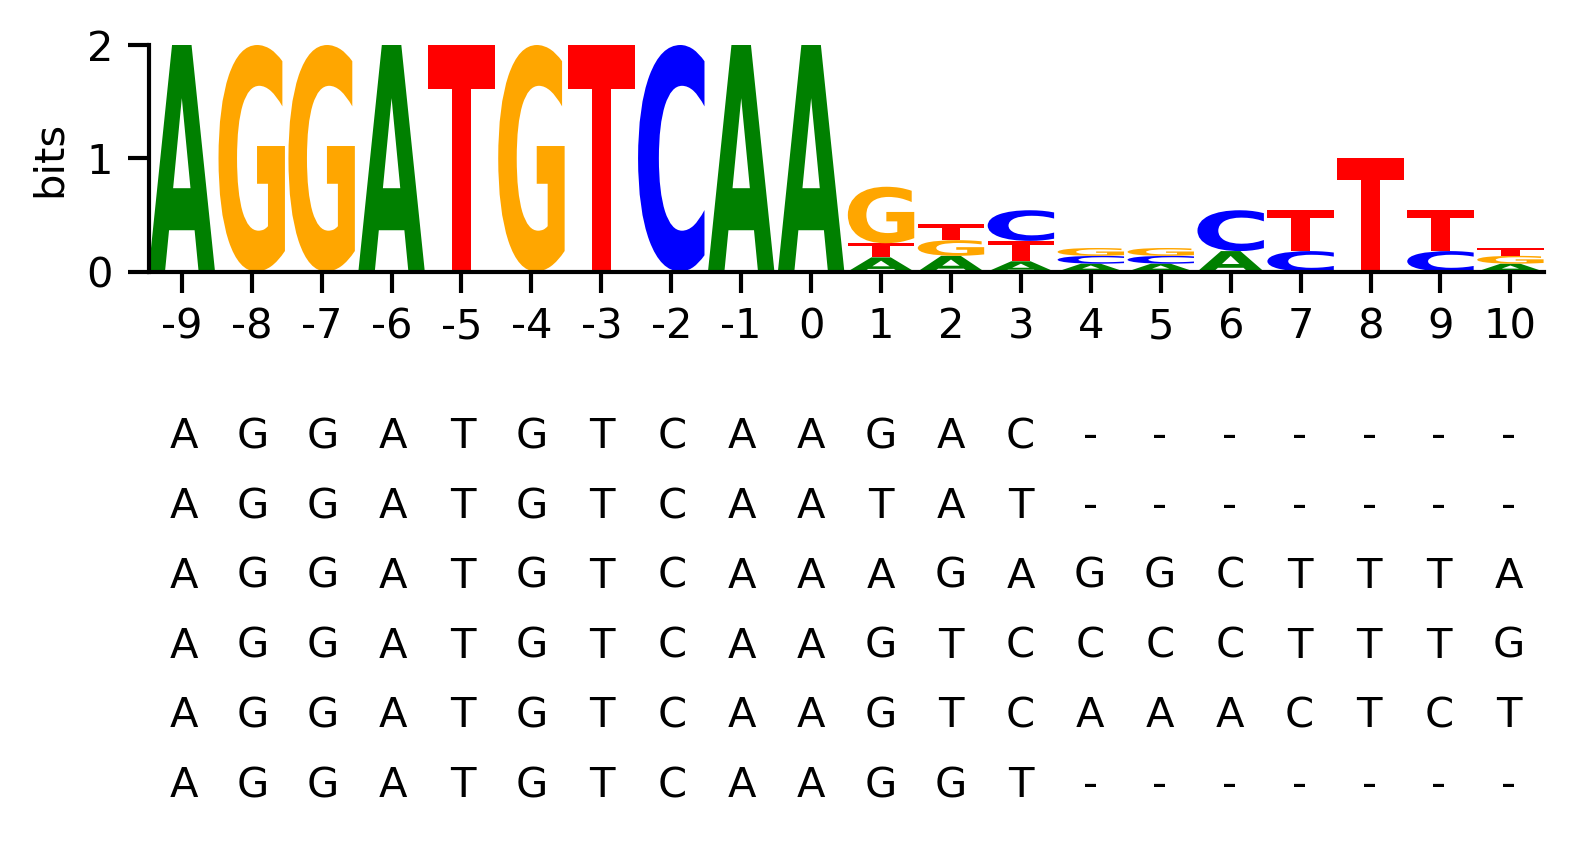

In [14]:
make_consensus_aln(aln_reshaped[2536-10:2536+10])

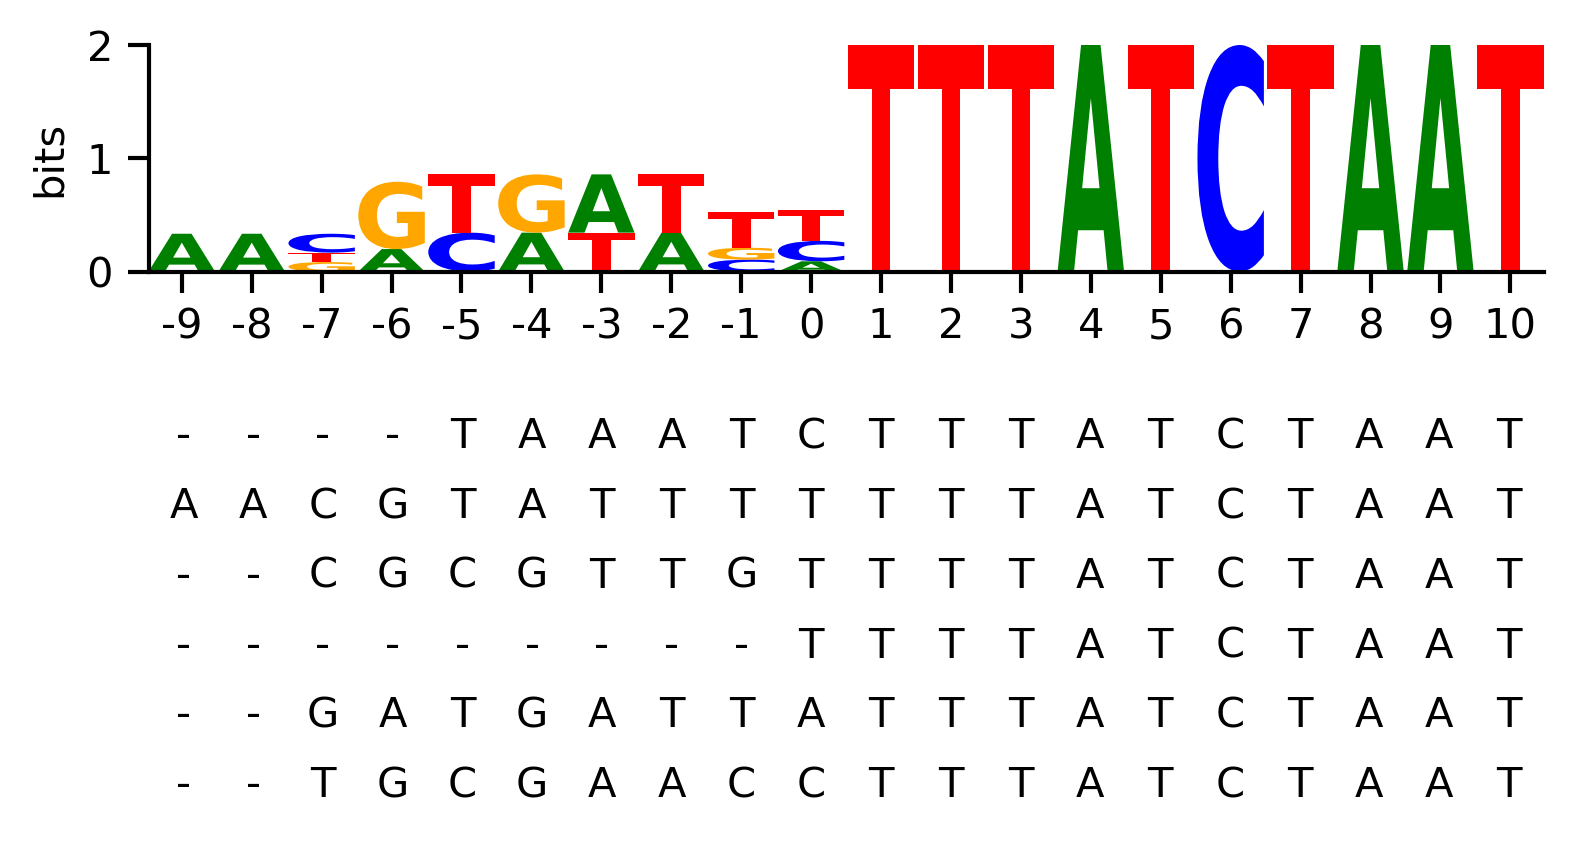

In [15]:
make_consensus_aln(aln_reshaped[712-10:712+10])